In [7]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor
import warnings
import xgboost as xgb
warnings.filterwarnings('ignore')

np.random.seed(42)
sns.set_theme()
train = pd.read_csv("data/track_k_ecommerce_returns_train.csv")
test = pd.read_csv("data/track_k_ecommerce_returns_test.csv")
X_train = train.drop(columns=['return_rate_pct'])
y_train = train[['return_rate_pct']]

X_test = test.drop(columns=['return_rate_pct'])
y_test = test[['return_rate_pct']]

##  Phase 3: Modeling & Evaluation
### 3.1 Establishing the Baseline: The Naive Approach (Mean Predictor)

In [41]:
def quick_test_model(model, X_train, y_train, X_test, y_test, return_model=False):
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

   


    print(f"Train MSE:{mean_squared_error(y_pred_train, y_train)}")
    print(f"Test MSE:{mean_squared_error(y_pred_test, y_test):.2f}")
    
    return model

   
from sklearn.dummy import DummyRegressor
quick_test_model(DummyRegressor(strategy='mean'), X_train, y_train, X_test, y_test)



Train MSE:528.876580666213
Test MSE:544.71


,strategy,'mean'
,constant,None
,quantile,None


**Baseline Results:** We selected the global mean of the target variable as our naive baseline model. As expected, this simplistic approach performs poorly, yielding a **Mean Squared Error (MSE) of 544.71**. 

**Next Steps:** This high error rate establishes our benchmark. Our primary objective moving forward is to iteratively train and tune more sophisticated machine learning models to capture the underlying patterns in the campaign data and progressively drive this MSE down.

### 3.3 Décision Trees

In [42]:
from sklearn import tree
DT= quick_test_model(tree.DecisionTreeRegressor(random_state=42), X_train, y_train, X_test, y_test)

Train MSE:1.7777814871266794e-36
Test MSE:51.07


**Results:** This approach achieved a **Test MSE of 51.07**, which is a substantial improvement over our naive baseline (544.71) and proves the model is learning valuable patterns.

**Evaluation Note:** However, the **Training MSE plummeted to an extremely low 1.78**. This massive discrepancy between training and testing error is a textbook example of severe **overfitting**. The single tree has essentially memorized the training data's noise rather than generalizing well to unseen campaigns. This limitation directly justifies our progression to an ensemble method to reduce variance.

### 3.4 Random Forest

In [43]:
RF = quick_test_model(RandomForestRegressor(n_estimators=100, random_state=42), X_train, y_train, X_test, y_test)

Train MSE:3.901080906892313
Test MSE:25.77


**Results:** The Random Forest model achieved an MSE of 25.77. This is a significant improvement and firmly outperforms all previous models we evaluated, making it our strongest approach for predicting campaign return rates.

**Evaluation Note:** However, it is important to note that the training MSE is significantly lower at 3.90. This large gap between the training error and the testing error suggests that the model is likely overfitting the training data.

### 3.5 Feature Importance Analysis

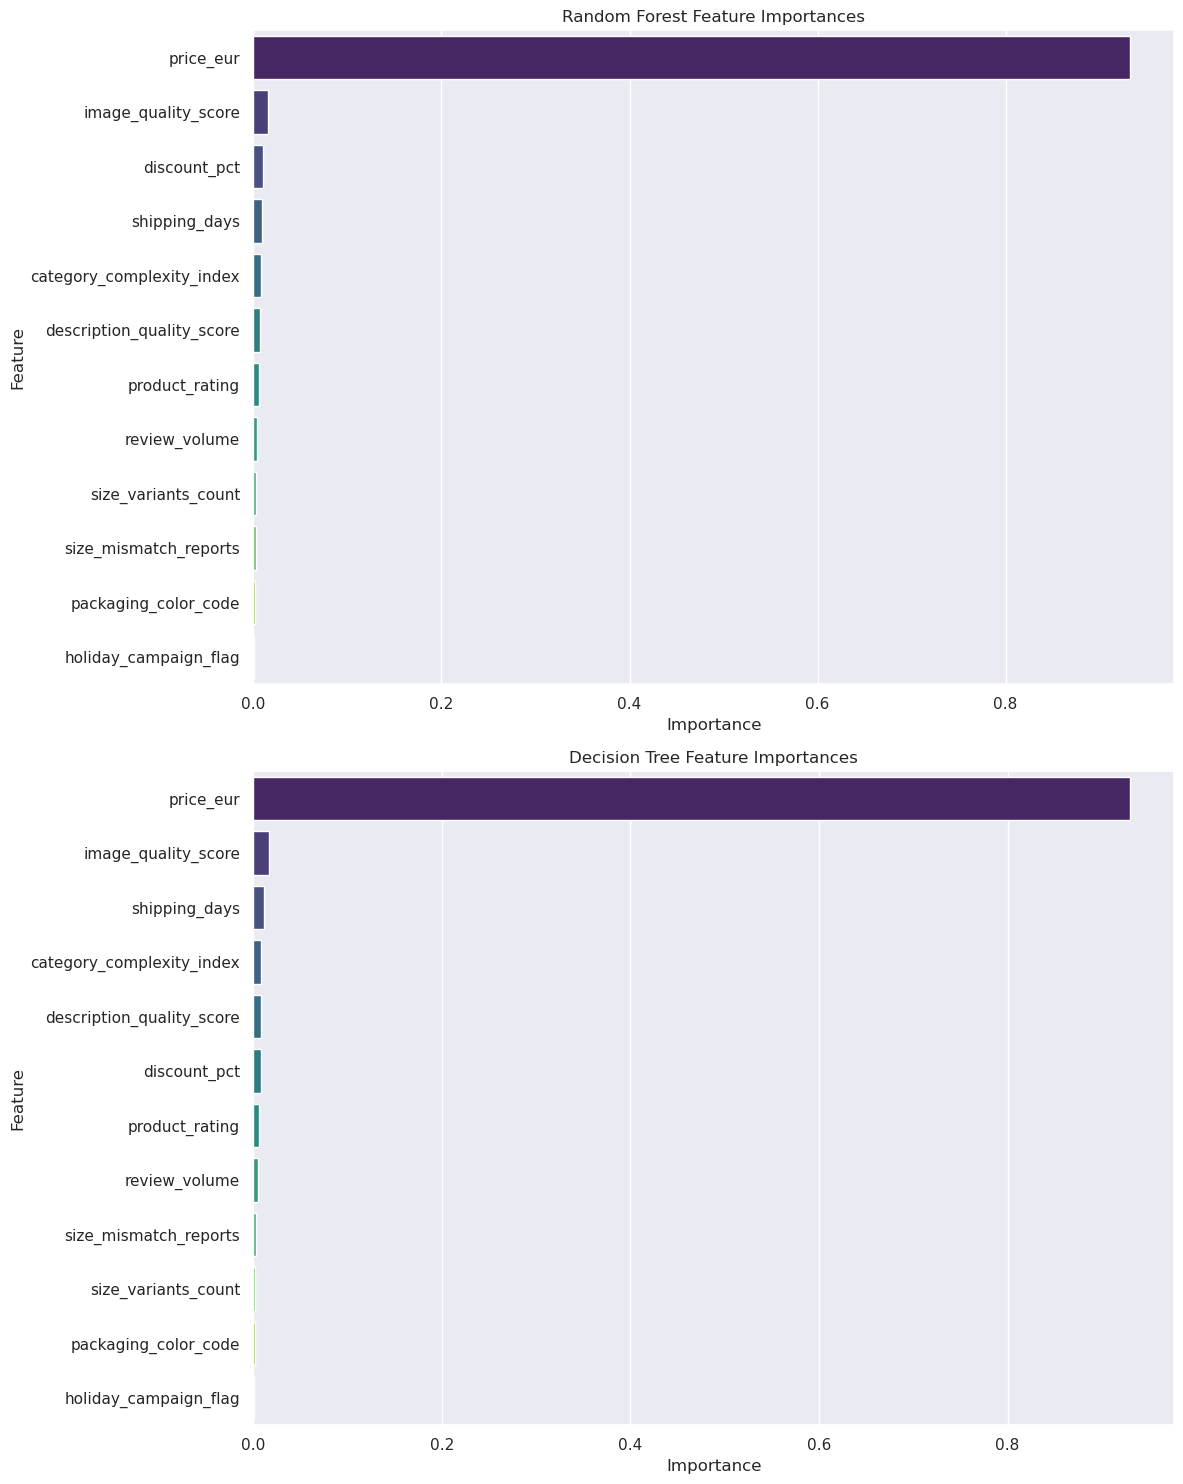

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(12, 15))

# Random Forest Feature Importances
importances = RF.feature_importances_
Feature_names = [col for col in X_train.columns]
feat_imp = pd.Series(importances, index=Feature_names).sort_values(ascending=False)

sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis", ax=axs[0])
axs[0].set_title("Random Forest Feature Importances")
axs[0].set_xlabel("Importance")
axs[0].set_ylabel("Feature")


# Decision Tree Feature Importances
importances = DT.feature_importances_
Feature_names = [col for col in X_train.columns]
feat_imp = pd.Series(importances, index=Feature_names).sort_values(ascending=False)

sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis", ax=axs[1])
axs[1].set_title("Decision Tree Feature Importances")
axs[1].set_xlabel("Importance")
axs[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()


After visualizing the feature importances for both the Random Forest and the Decision Tree, a very clear and consistent pattern emerges. 

**Key Observations:**
* **Price Dominance:** `Price` is by far the most important predictor of campaign return rates. This perfectly aligns with our earlier Exploratory Data Analysis, where `Price` showed the strongest correlation on the heatmap.
* **Secondary Drivers:** The `Image Quality Score` consistently ranks as the second most influential feature for both models.
* **Model Agreement:** Notably, both the Random Forest and the Decision Tree utilize the exact same features in the exact same order of importance. This unanimous agreement between the models gives us high confidence that we have identified the true primary drivers of return risk.